# Lab: Edge Detection


## Goal of this lab

After having learned about the 2D convolution and smoothing filters for noise reduction, we will have a look at filters for edge detection in this lab. The main algorithm applied therefore is again the 2D convolution but the filter will look different

* Computing image gradients
* Defining filters for the detection of horizontal and vertical edges
* Defining filters for the detection of arbitrarily oriented edges
* Image Sharpening
* The Canny edge detector
* Define your own filter

Required packages

* numpy
* matplotlib
* scipy
* scikit-image


You can execute individual code blocks by pressing SHIFT+Enter consecutively.

You can trigger auto completion with TABULATOR


## Import required packages

In [1]:
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt
from scipy import signal
import imageio
from skimage import color
import imageio.v2 as imageio

## Exercise 1: Defining an edge detection filter

The simplest possible edge detection filter is just to compute the horizontal / vertical gradient (i.e. the difference between horizontal / vertical neighboring pixels. 

1. Load the image tiger.bmp with *imageio.imread()*.
2. Define two filters that compute the horizontal and the vertical gradient. 
3. Apply both filters to the image (separately) and show the two results. Note: before you filter the images, convert the image to datatype float, i.e. myIm = myIm.astype("float32")
4. Interprete which filter extracts which edges
5. Show what happens if we apply both filters (one after the other) to the image
6. What is the new value range of the images? Explain why the value range has changed 

Note: do not expect to get perfect edges out of this operation. This example should just illustrate how the gradients look like.

To plot the input image and the filtered result image use the following code (im_in and im_out are the input and output images):
~~~python
SIZE = 20;
f, (ax1, ax2) = plt.subplots(1, 2,figsize=(SIZE,5*SIZE))
ax1.imshow(im_in,cmap='gray') 
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out,cmap='gray') 
ax2.set_title('Output')
ax2.axis('off')
plt.show(f)
~~~

Note: adjust SIZE to your preferences (it scales up or down the result image)

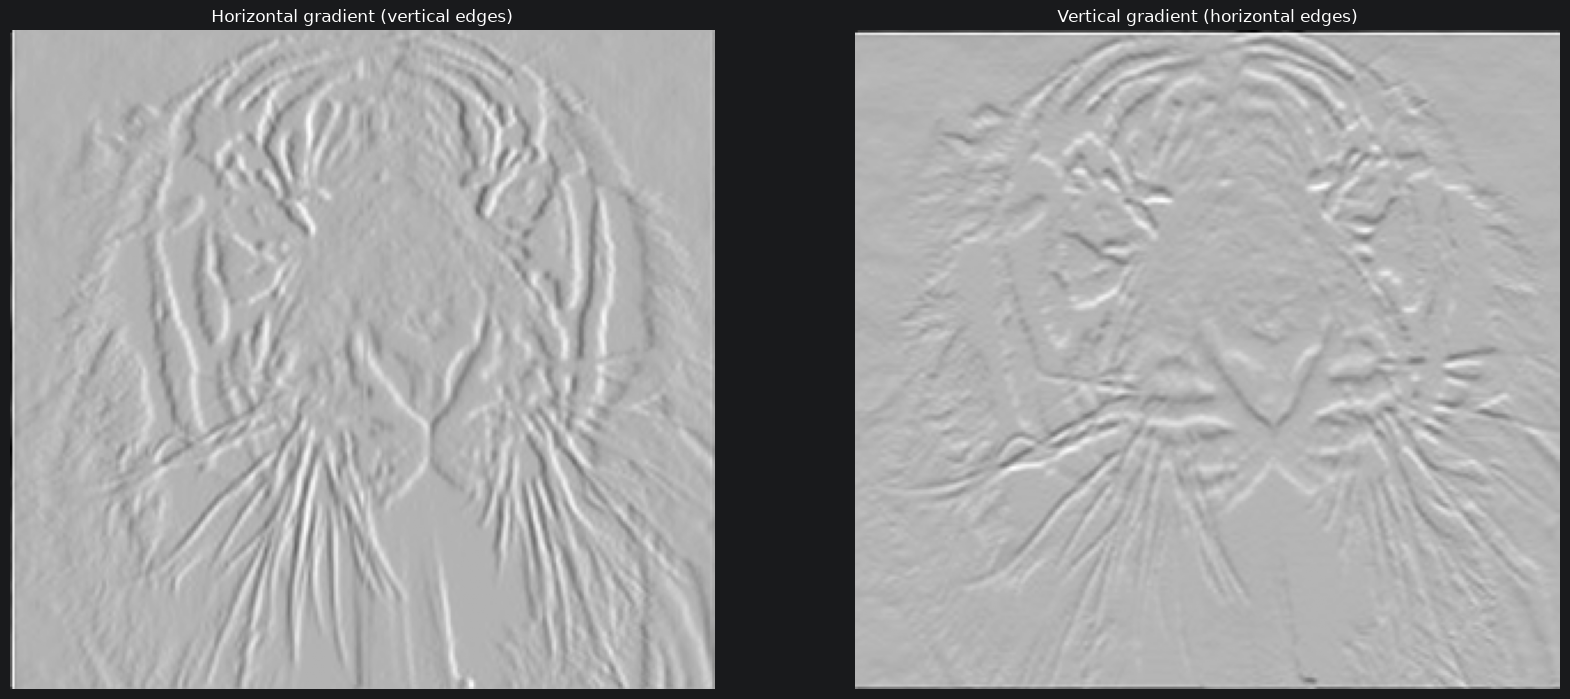

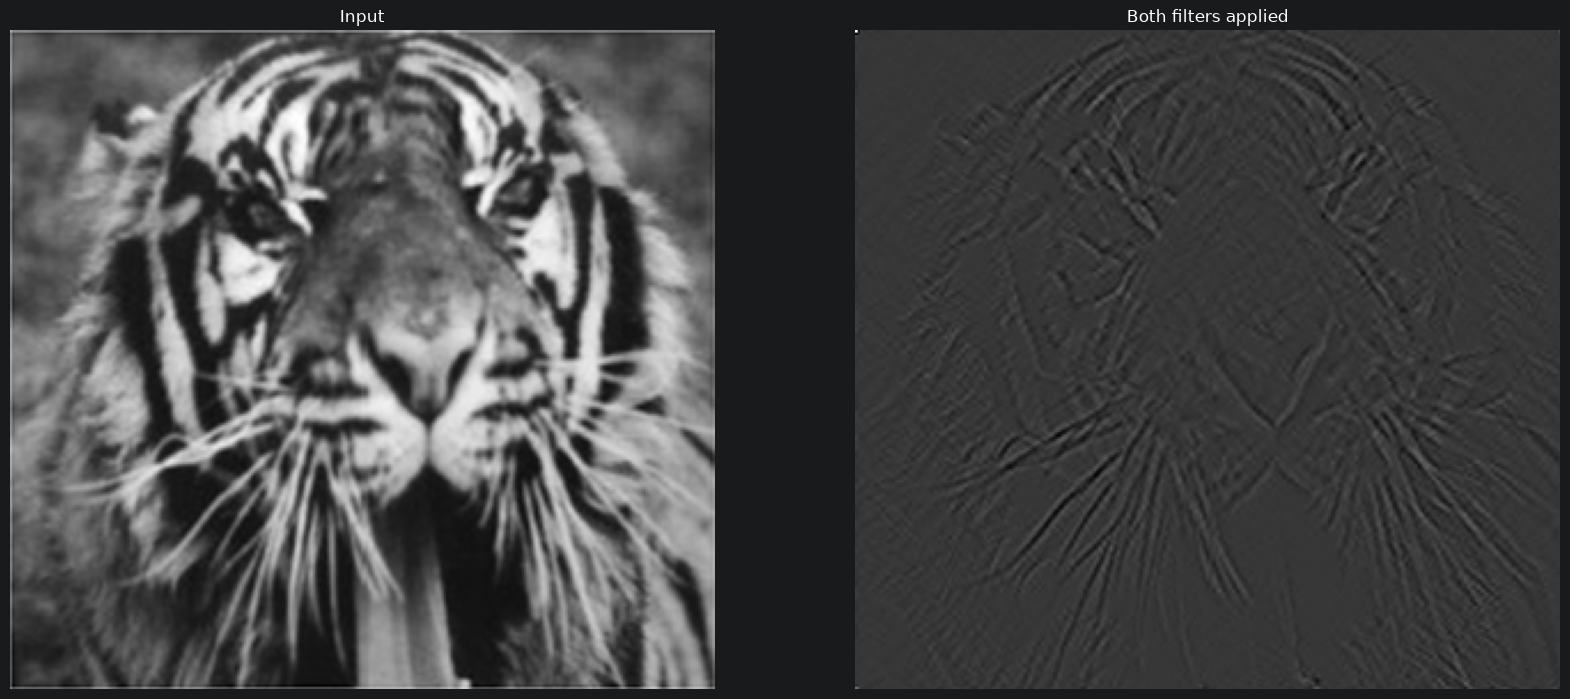

Horizontal: -187.0 to 79.0
Vertical:   -206.0 to 85.0
Combined:   -47.0 to 170.0


In [2]:
im = imageio.imread('../../data/test_images/tiger.bmp').astype('float32')
if im.ndim == 3:
    im = color.rgb2gray(im)

grad_h = np.array([[-1, 1]])
grad_v = np.array([[-1], [1]])

im_h = signal.convolve2d(im, grad_h, mode='same')
im_v = signal.convolve2d(im, grad_v, mode='same')

SIZE = 10
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE*2, SIZE))
ax1.imshow(im_h, cmap='gray')
ax1.set_title('Horizontal gradient (vertical edges)')
ax1.axis('off')
ax2.imshow(im_v, cmap='gray')
ax2.set_title('Vertical gradient (horizontal edges)')
ax2.axis('off')
plt.show()

im_both = signal.convolve2d(im_h, grad_v, mode='same')
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE*2, SIZE))
ax1.imshow(im, cmap='gray')
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_both, cmap='gray')
ax2.set_title('Both filters applied')
ax2.axis('off')
plt.show()

print(f'Horizontal: {im_h.min():.1f} to {im_h.max():.1f}')
print(f'Vertical:   {im_v.min():.1f} to {im_v.max():.1f}')
print(f'Combined:   {im_both.min():.1f} to {im_both.max():.1f}')

**Answers**

- `grad_h` detects vertical edges (intensity changes along x).
- `grad_v` detects horizontal edges (intensity changes along y).
- Applying both filters in sequence highlights corner-like regions where both horizontal and vertical changes occur.
- The output range goes negative because the filter computes signed differences instead of absolute values.
- Chaining both filters widens the range further, since differences of differences accumulate.

## Exercise 2: Defining simple edge filters for horizontal and vertical edges


1. Define the following edge filters and apply them separately to image "tiger.bmp" and plot the result:

\begin{equation}
   P1 = \begin{bmatrix}
         -1 & 0 & 0 & 0 & 1 \\
         -1 & 0 & 0 & 0 & 1 \\
         -1 & 0 & 0 & 0 & 1 \\
         -1 & 0 & 0 & 0 & 1 \\
         -1 & 0 & 0 & 0 & 1 
     \end{bmatrix}
\end{equation}

\begin{equation}
   P2 = \begin{bmatrix}
         -1 & -1 & -1 & -1 & -1 \\
         0 & 0 & 0 & 0 & 0 \\
         0 & 0 & 0 & 0 & 0 \\
         0 & 0 & 0 & 0 & 0 \\
         1 & 1 & 1 & 1 & 1 
     \end{bmatrix}
\end{equation}
   
Note: use the np.transpose function to save yourself work

Note: be sure to convert the image to float32 first!

2. Generate binary edge images: empirically find a treshhold value and set all values in the two result images below the threshold to 0 and all values above to 1. Find a threshold that brings out the edges well.

3. Define a Sobel operator for horizontal and vertical edges (see Lecture slides or https://de.wikipedia.org/wiki/Sobel-Operator) and apply it to image Camera_obscura.jpg. Firstly, load the image with *imageio.imread()*, check the shape of the image and if necessary convert the image into a grayscale image by using *color.rgb2gray()*. Apply each filter to the image and compute and show the resulting images. To combine the two filters you need to implement the following formula $G = sqrt(G_x^2 + G_y^2)$. Another common approach (which approximates the final result) is to use the sum of the absolute directional values $G = abs(G_x)+abs(G_y)$. Show the final results obtained with both methods.

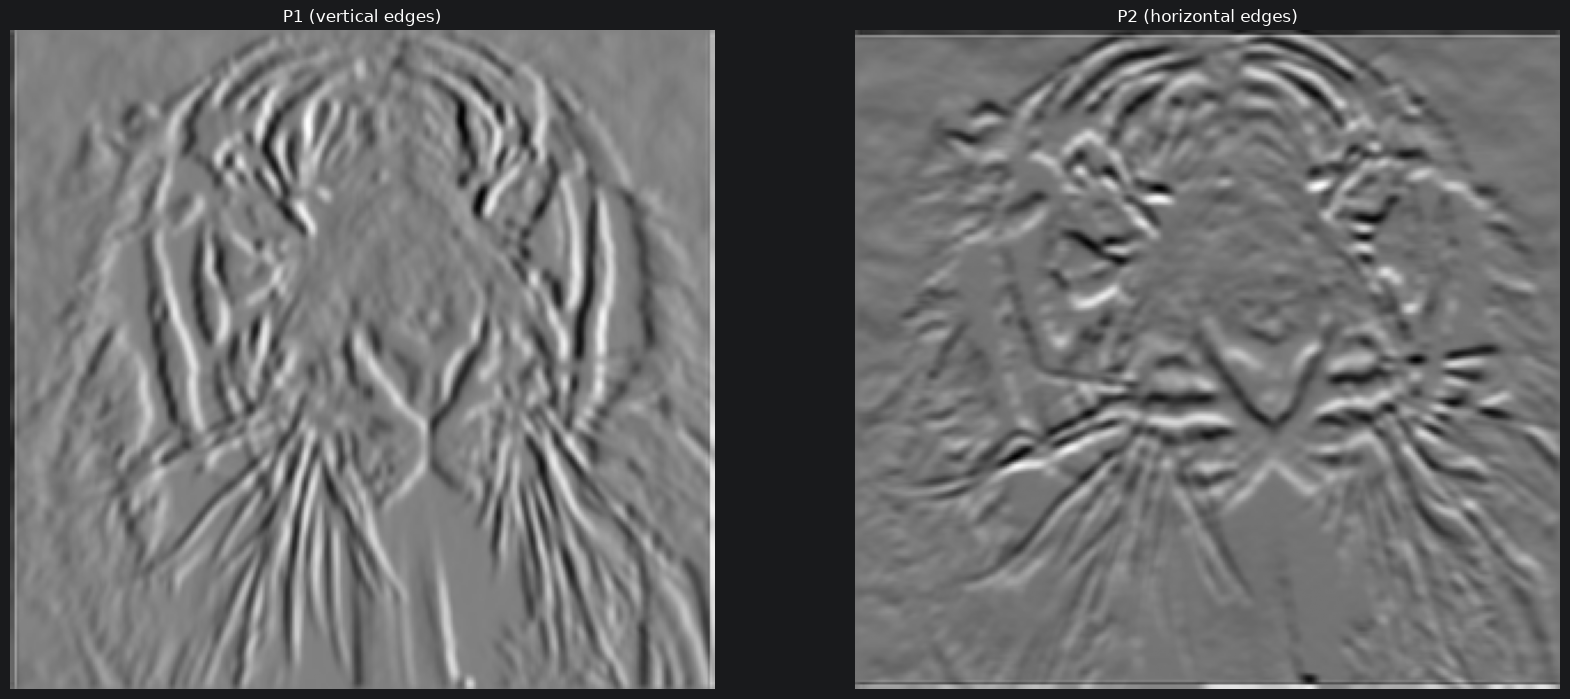

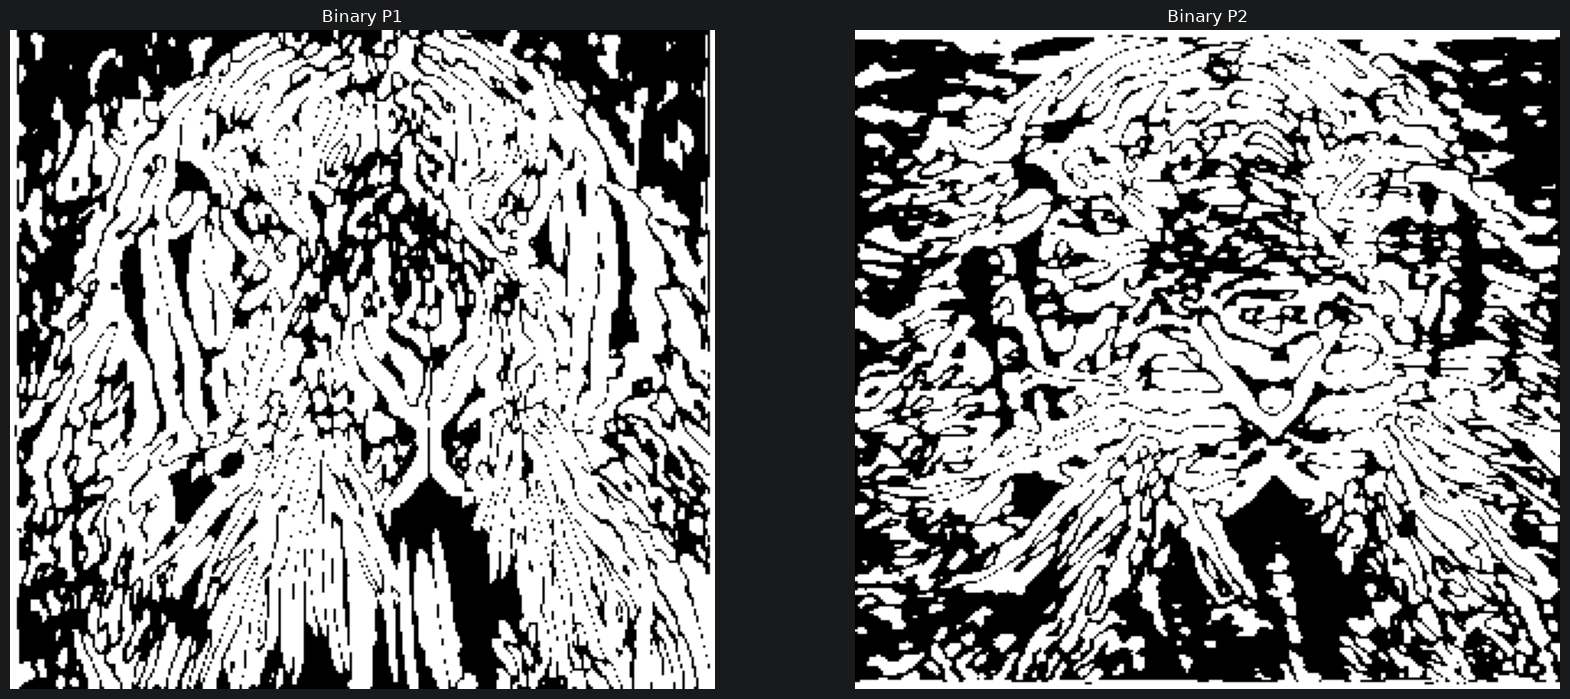

Camera_obscura shape: (580, 363, 3)


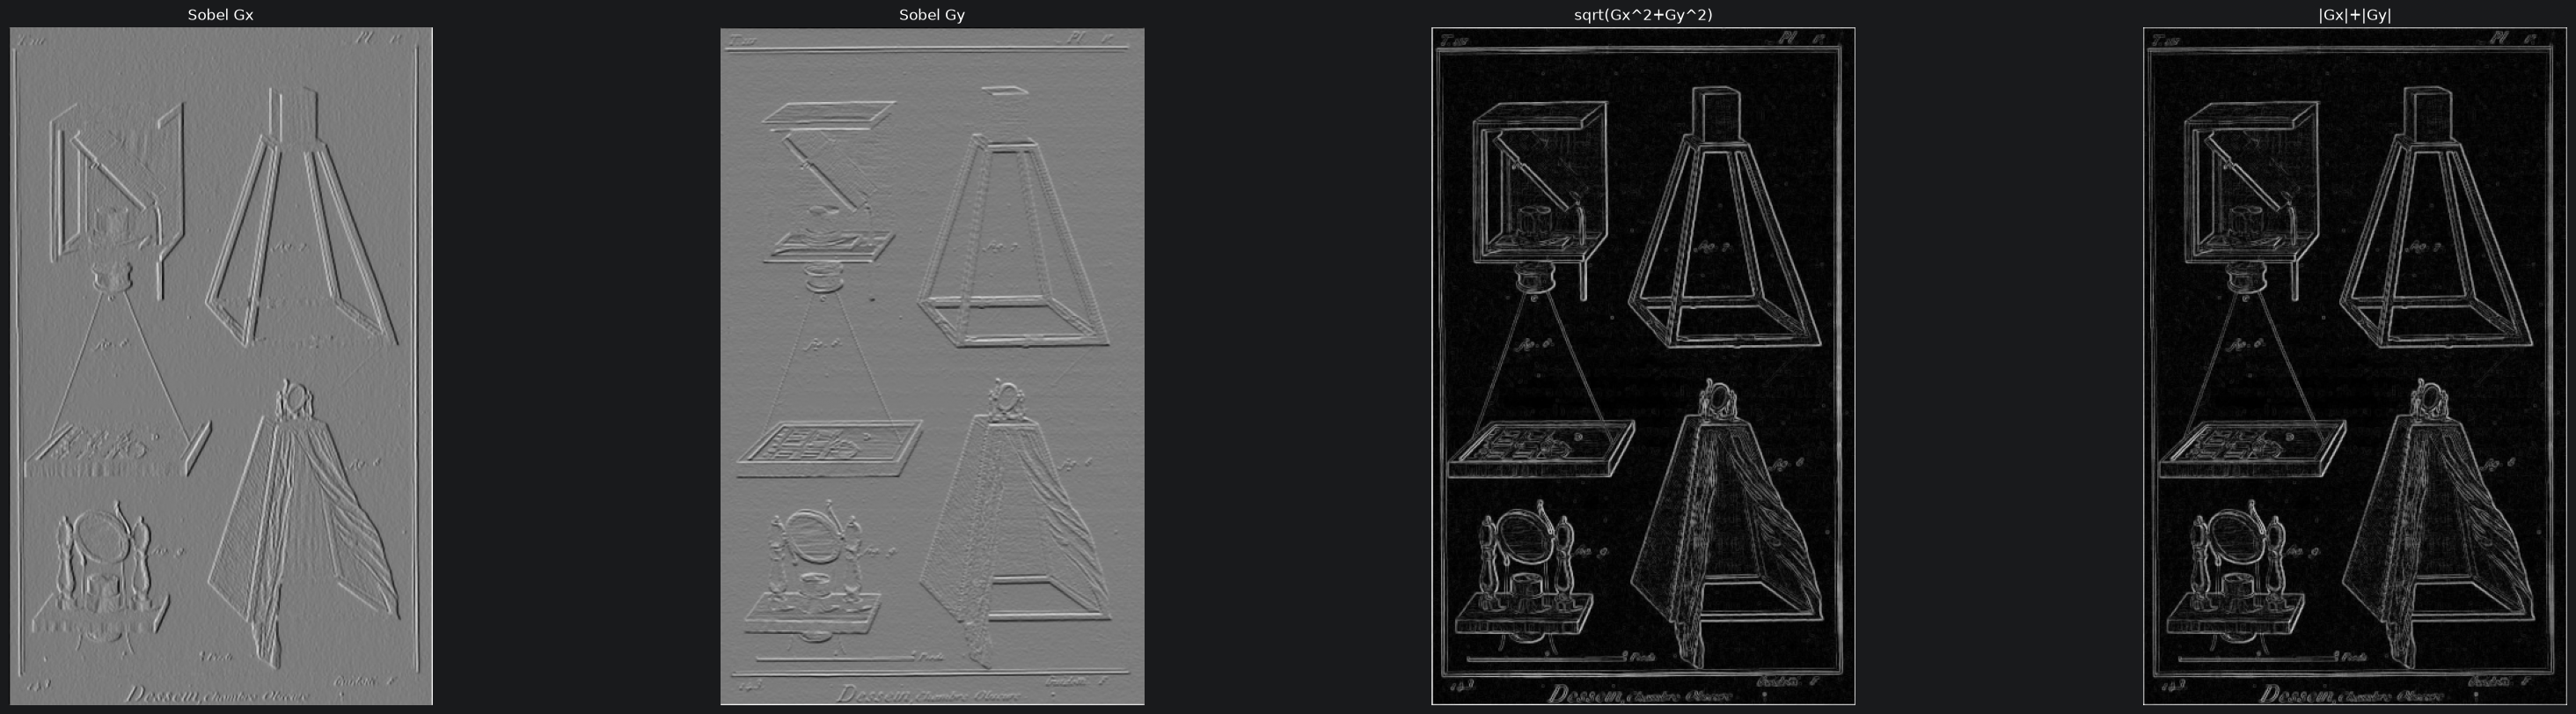

In [3]:
im = imageio.imread('../../data/test_images/tiger.bmp').astype('float32')
if im.ndim == 3:
    im = color.rgb2gray(im)

P1 = np.array([[-1, 0, 0, 0, 1],
               [-1, 0, 0, 0, 1],
               [-1, 0, 0, 0, 1],
               [-1, 0, 0, 0, 1],
               [-1, 0, 0, 0, 1]], dtype='float32')
P2 = np.transpose(P1)

im_p1 = signal.convolve2d(im, P1, mode='same')
im_p2 = signal.convolve2d(im, P2, mode='same')

SIZE = 10
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE*2, SIZE))
ax1.imshow(im_p1, cmap='gray')
ax1.set_title('P1 (vertical edges)')
ax1.axis('off')
ax2.imshow(im_p2, cmap='gray')
ax2.set_title('P2 (horizontal edges)')
ax2.axis('off')
plt.show()

threshold = 50
im_p1_bin = (np.abs(im_p1) > threshold).astype('float32')
im_p2_bin = (np.abs(im_p2) > threshold).astype('float32')

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE*2, SIZE))
ax1.imshow(im_p1_bin, cmap='gray')
ax1.set_title('Binary P1')
ax1.axis('off')
ax2.imshow(im_p2_bin, cmap='gray')
ax2.set_title('Binary P2')
ax2.axis('off')
plt.show()

im_cam = imageio.imread('../../data/test_images/Camera_obscura.jpg').astype('float32')
print('Camera_obscura shape:', im_cam.shape)
if im_cam.ndim == 3:
    im_cam = color.rgb2gray(im_cam)

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype='float32')
sobel_y = np.transpose(sobel_x)

Gx = signal.convolve2d(im_cam, sobel_x, mode='same')
Gy = signal.convolve2d(im_cam, sobel_y, mode='same')
G_sqrt = np.sqrt(Gx**2 + Gy**2)
G_abs  = np.abs(Gx) + np.abs(Gy)

f, axes = plt.subplots(1, 4, figsize=(SIZE*4, SIZE))
for ax, img, title in zip(axes, [Gx, Gy, G_sqrt, G_abs],
                          ['Sobel Gx', 'Sobel Gy', 'sqrt(Gx^2+Gy^2)', '|Gx|+|Gy|']):
    ax.imshow(img, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.show()

## Exercise 3: Defining an edge filter for arbitrarily oriented edges

1. Load the image SanFrancisco.jpg with *imageio.imread()*, check the shape of the image and if necessary convert the image into a grayscale image by using *color.rgb2gray()*
2. Apply a laplacian filter of size 3x3 (see lecture slides) to the input image SanFrancisco.jpg
3. Compute the absolute value of the output
4. Plot input, laplace filtered image and the image with the absolute values


Note: be sure to convert the image to float32 first!



SanFrancisco shape: (168, 300, 3)


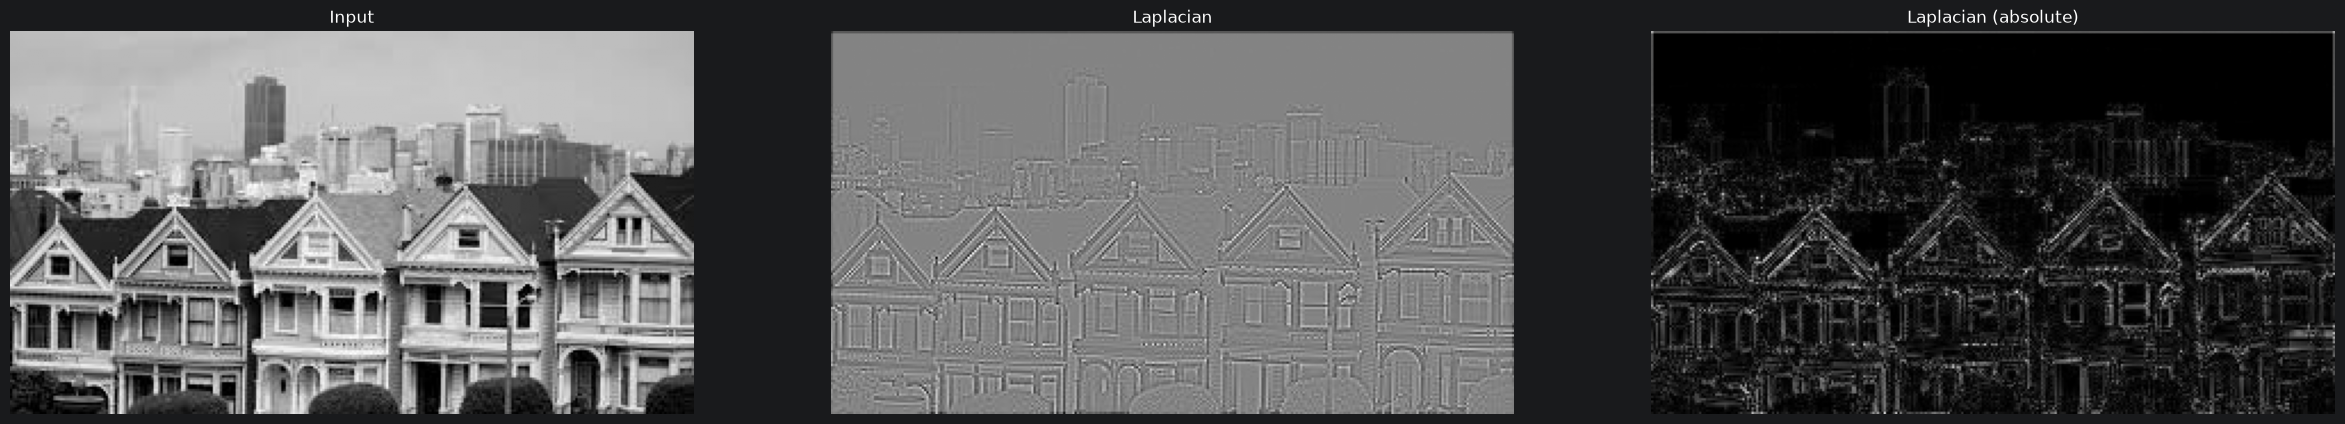

In [4]:
im_sf = imageio.imread('../../data/test_images/SanFrancisco.jpg').astype('float32')
print('SanFrancisco shape:', im_sf.shape)
if im_sf.ndim == 3:
    im_sf = color.rgb2gray(im_sf)

laplacian = np.array([[ 0,  1,  0],
                      [ 1, -4,  1],
                      [ 0,  1,  0]], dtype='float32')

im_lap = signal.convolve2d(im_sf, laplacian, mode='same')
im_lap_abs = np.abs(im_lap)

SIZE = 10
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(SIZE*3, SIZE))
ax1.imshow(im_sf, cmap='gray'); ax1.set_title('Input'); ax1.axis('off')
ax2.imshow(im_lap, cmap='gray'); ax2.set_title('Laplacian'); ax2.axis('off')
ax3.imshow(im_lap_abs, cmap='gray'); ax3.set_title('Laplacian (absolute)'); ax3.axis('off')
plt.show()

## Exercise 4: Sharpening an image

You can use the following filter (which is similar to the laplace filter) to sharpen an image:

\begin{equation}
   P1 = \begin{bmatrix}
         0  & -1 & 0  \\
         -1 & 5  & -1  \\
         0  & -1 & 0 
     \end{bmatrix}
\end{equation}

1. Read in tiger.bmp, define the sharpening filter and apply it
2. Plot the result
3. The result will have rather low contrast. Apply histogram equalization to enhance the contrast. Plot the result. Did the image improve? Are there new artifacts?

Note: for histogram equalization first run: "from skimage import exposure" and then run A = exposure.equalize_hist(myImage) to enhance the contrast.


Note: be sure to convert the image to float32 first

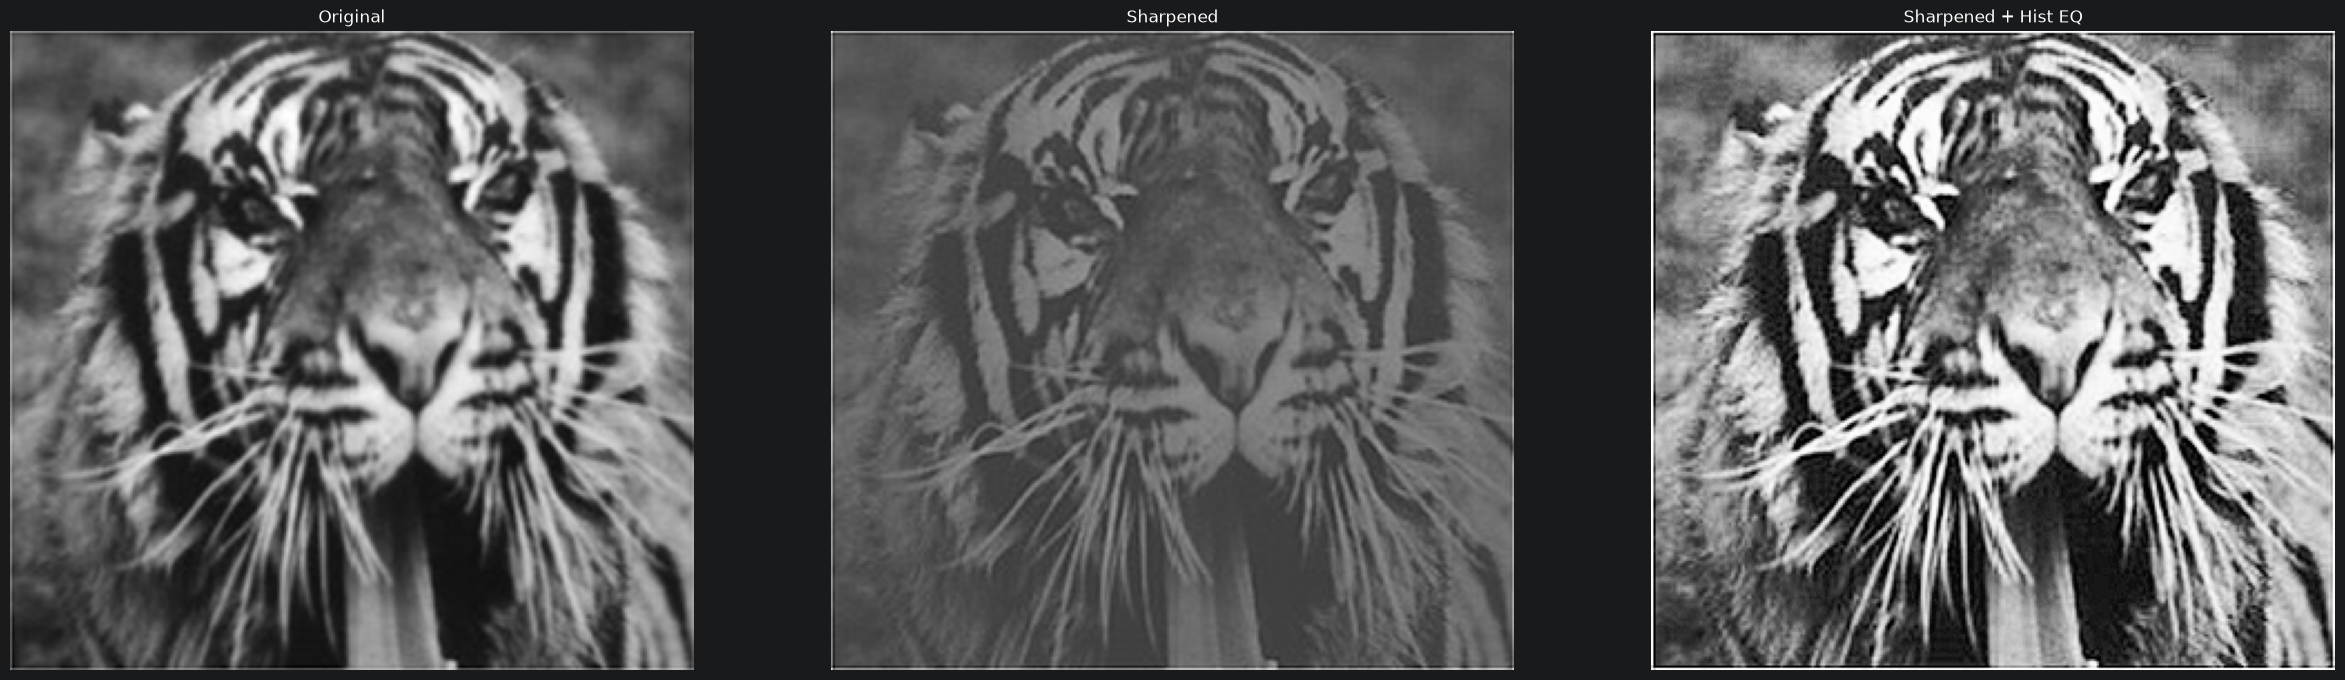

In [5]:
from skimage import exposure

im = imageio.imread('../../data/test_images/tiger.bmp').astype('float32')
if im.ndim == 3:
    im = color.rgb2gray(im)

sharpen = np.array([[ 0, -1,  0],
                    [-1,  5, -1],
                    [ 0, -1,  0]], dtype='float32')

im_sharp = signal.convolve2d(im, sharpen, mode='same')
im_sharp_eq = exposure.equalize_hist(im_sharp)

SIZE = 10
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(SIZE*3, SIZE))
ax1.imshow(im, cmap='gray'); ax1.set_title('Original'); ax1.axis('off')
ax2.imshow(im_sharp, cmap='gray'); ax2.set_title('Sharpened'); ax2.axis('off')
ax3.imshow(im_sharp_eq, cmap='gray'); ax3.set_title('Sharpened + Hist EQ'); ax3.axis('off')
plt.show()

**Answers**

- The sharpened image looks somewhat flat; histogram equalization restores contrast.
- The image does improve in perceived sharpness and contrast.
- Halo artifacts appear around strong edges, and noise is amplified.

## Exercise 5: The Canny edge detector


1. Good news: we will not implement it from scratch! There is an implementation in scikit-image!
2. Import scikit-image: from skimage import feature
3. Run the canny edge detector on the image SanFrancisco.jpg (function: feature.canny). Note: to see how to use the function, search for the API reference of scikit-image.
4. According to the API reference, the function has a number of parameters. Play around with the different parameters and plot the results. What do the individual parameters influence? Write down your interpretation in the markup below.


Note: be sure to convert the input image to float32 first!


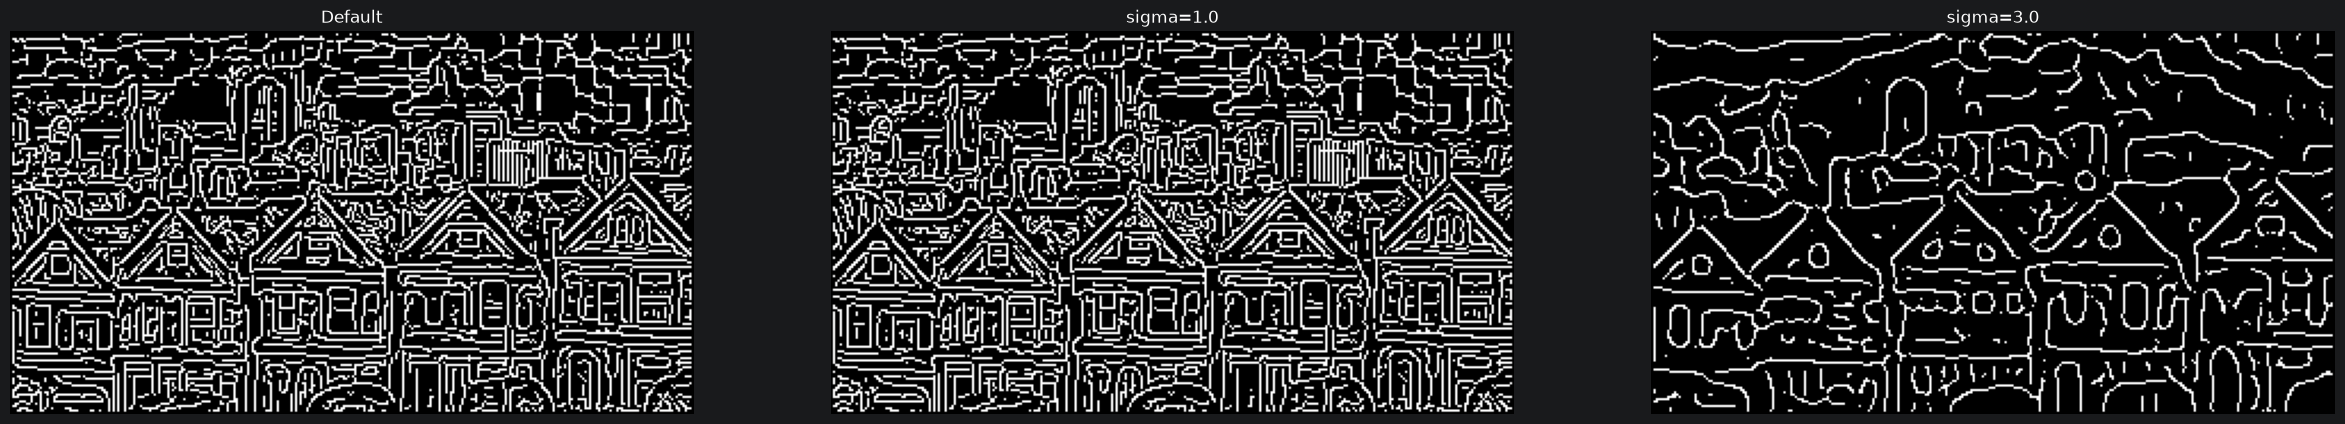

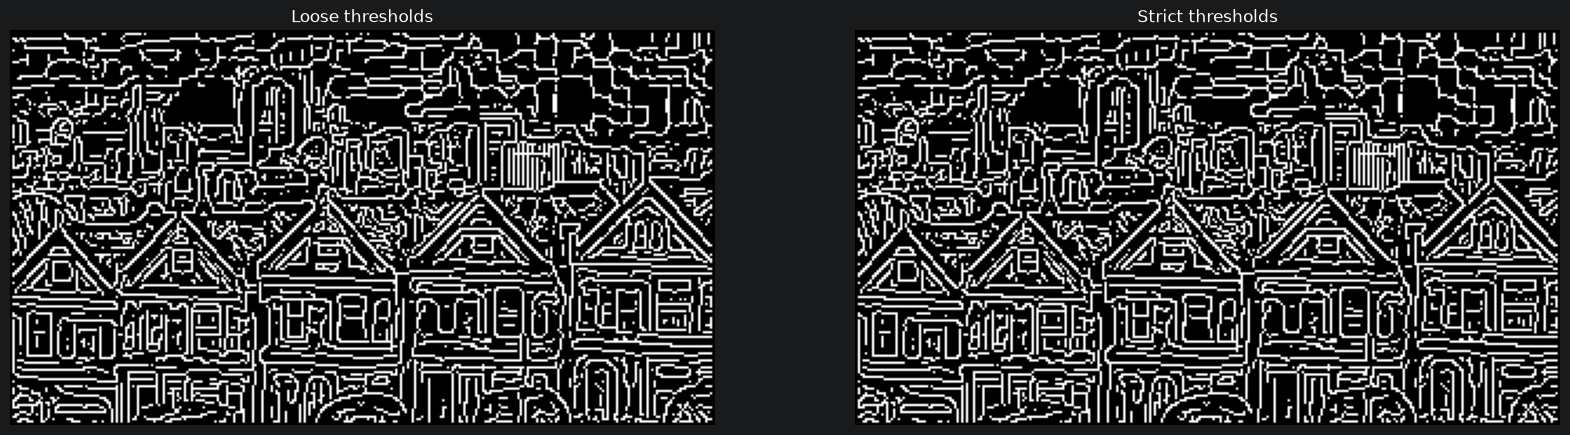

In [6]:
from skimage import feature

im_sf = imageio.imread('../../data/test_images/SanFrancisco.jpg').astype('float32')
if im_sf.ndim == 3:
    im_sf = color.rgb2gray(im_sf)

SIZE = 10

edges_default    = feature.canny(im_sf)
edges_low_sigma  = feature.canny(im_sf, sigma=1.0)
edges_high_sigma = feature.canny(im_sf, sigma=3.0)
edges_loose      = feature.canny(im_sf, sigma=1.0, low_threshold=0.05, high_threshold=0.1)
edges_strict     = feature.canny(im_sf, sigma=1.0, low_threshold=0.2,  high_threshold=0.4)

f, axes = plt.subplots(1, 3, figsize=(SIZE*3, SIZE))
for ax, img, title in zip(axes, [edges_default, edges_low_sigma, edges_high_sigma],
                          ['Default', 'sigma=1.0', 'sigma=3.0']):
    ax.imshow(img, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.show()

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE*2, SIZE))
ax1.imshow(edges_loose, cmap='gray'); ax1.set_title('Loose thresholds'); ax1.axis('off')
ax2.imshow(edges_strict, cmap='gray'); ax2.set_title('Strict thresholds'); ax2.axis('off')
plt.show()

Your interpretation of the parameters of canny go here:

- **sigma**: controls the initial Gaussian blur. Higher sigma smooths out more noise, giving fewer but cleaner edges.
- **low_threshold**: minimum gradient needed to even consider a pixel as an edge candidate. Lower = more edges included.
- **high_threshold**: pixels above this are kept as definite edges. Higher = only the strongest edges survive.
- The two thresholds work through **hysteresis**: weak pixels (between low and high) are only kept if they connect to a strong edge ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿ this avoids isolated noise being treated as edges.

## Exercise 6: Define your own effect filter


Take an arbitrary input image and apply your own effect filter on it! 

You can create interesting effects by convolving the image with some filter and then e.g. subtracting this result from the original image. 


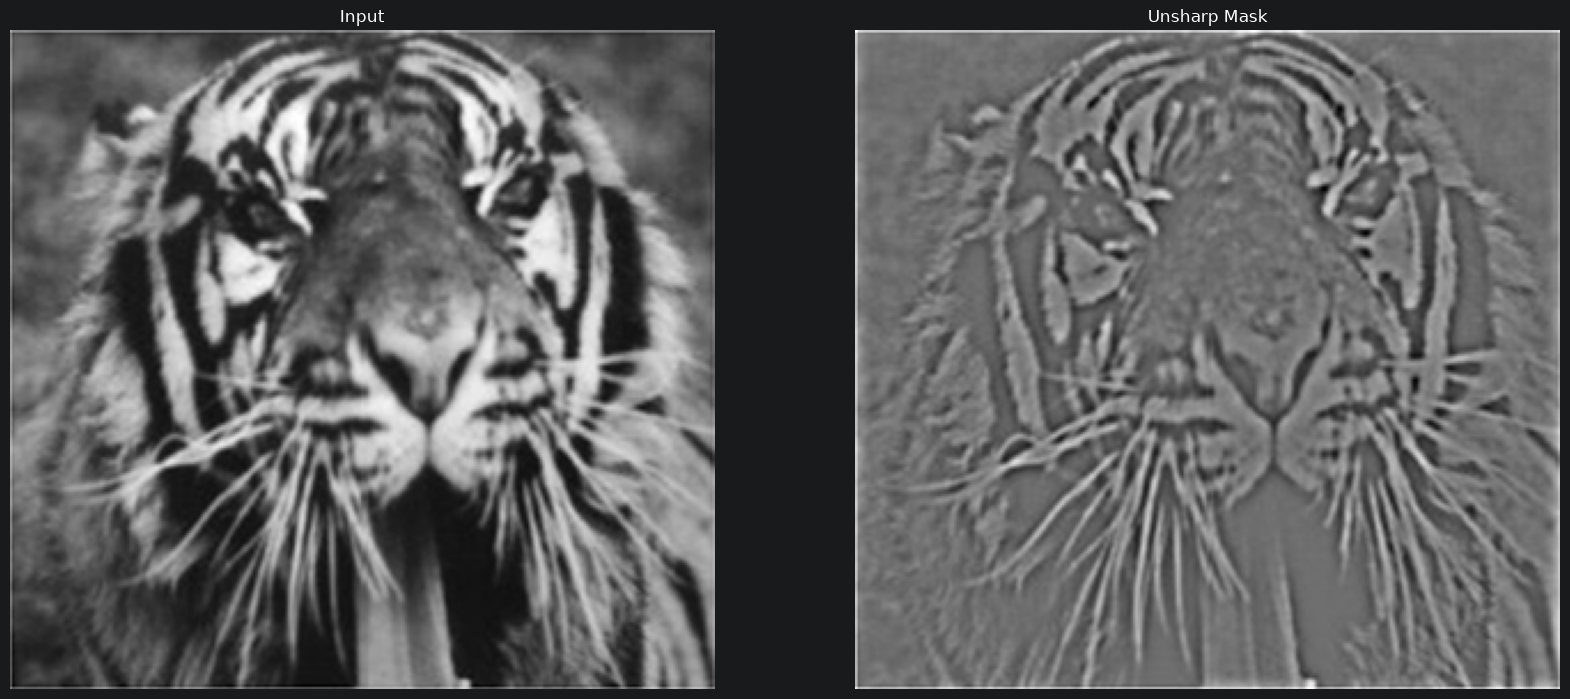

In [7]:
im = imageio.imread('../../data/test_images/tiger.bmp').astype('float32')
if im.ndim == 3:
    im = color.rgb2gray(im)

def gauss2D(shape=(3, 3), sigma=0.5):
    m, n = [(ss - 1.) / 2. for ss in shape]
    y, x = np.ogrid[-m:m+1, -n:n+1]
    h = np.exp(-(x*x + y*y) / (2. * sigma * sigma))
    h[h < np.finfo(h.dtype).eps * h.max()] = 0
    sumh = h.sum()
    if sumh != 0:
        h /= sumh
    return h

blur = gauss2D(shape=(15, 15), sigma=3.0)
im_blurred = signal.convolve2d(im, blur, mode='same')
im_unsharp = im - im_blurred

SIZE = 10
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE*2, SIZE))
ax1.imshow(im, cmap='gray'); ax1.set_title('Input'); ax1.axis('off')
ax2.imshow(im_unsharp, cmap='gray'); ax2.set_title('Unsharp Mask'); ax2.axis('off')
plt.show()